# Effect of Blur and Sharpening on Object Detection
**Alok Sahni | G25AIT2138 | g25ait2138@iitj.ac.in**  
Foundations of Vision and Language — Individual Mini CV Project

This completed notebook compares pretrained YOLO11n on the same 128 COCO128 images under Original, Gaussian Blur and Sharpened conditions. All three validation runs and nine annotated prediction images are retained from the supplied executed T4 notebook.

**Run provenance:** supplied archive, `23-10-26/gpt/T4GPU/G25AIT2138_FoVL_Individual_Project_CV (1).ipynb`. Saved logs report Ultralytics 8.4.184, Python 3.13.15, PyTorch 2.11.0+cu130 and Tesla T4. Model inference was not rerun during this consolidation. Code and recorded execution outputs are preserved; the final summary and submission answers below were added from those outputs.

**Method:** one pretrained model, no retraining; validation uses image size 640 and batch size 16. Stage 2 applies `cv2.GaussianBlur(image, (9, 9), 0)` to every original image. Stage 3 applies unsharp masking to the saved blurred images: `1.5 * blurred - 0.5 * GaussianBlur(blurred, sigma=1.0)`, using saturating uint8 arithmetic. Labels are retained, including the two background images. Prediction examples use confidence 0.25 and identical filenames at every stage.

**Reproduction:** run all code cells in order in Google Colab. Installation currently upgrades dependencies, so a future run may differ from these saved results. Use the recorded environment when seeking close replication. Validation defaults are inherited from that Ultralytics version. Results measure this small COCO128 experiment, not performance on an independent deployment test set. JPEG re-encoding of processed images is also part of this pipeline.


## Setup 1 — Install Packages

In [1]:
!pip -q install -U ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 7.8 MB/s eta 0:00:00


## Setup 2 — Download COCO128

In [2]:
from pathlib import Path
import urllib.request
import zipfile
import os

# Google Colab → /content/datasets
# Local/Jupyter/GPU server → ~/fvl_datasets
if Path("/content").exists() and os.access("/content", os.W_OK):
    DATA_ROOT = Path("/content/datasets")
else:
    DATA_ROOT = Path.home() / "fvl_datasets"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

zip_path = DATA_ROOT / "coco128.zip"
dataset_dir = DATA_ROOT / "coco128"

if not dataset_dir.exists():
    url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"

    print("Downloading COCO128 to:", zip_path)
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_ROOT)

    print("Download and extraction complete.")
else:
    print("COCO128 already exists.")

print("Dataset ready at:", dataset_dir)
print("Images:", dataset_dir / "images" / "train2017")
print("Labels:", dataset_dir / "labels" / "train2017")

Download and extraction complete.
Dataset ready at: /content/datasets/coco128
Images: /content/datasets/coco128/images/train2017
Labels: /content/datasets/coco128/labels/train2017


## Setup 3 — Load Pretrained YOLO11n

In [3]:
from pathlib import Path
import os
from ultralytics import YOLO

PROJECT_ROOT = Path('/content/fvl_project') if Path('/content').exists() else Path.home() / 'fvl_project'
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
model = YOLO('yolo11n.pt')  # one fixed pretrained model for all three stages
print('Project folder:', PROJECT_ROOT)
print('Model: YOLO11n (pretrained; no retraining)')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Project folder: /content/fvl_project
Model: YOLO11n (pretrained; no retraining)



# Stage 1 — Baseline on Original Images

### Your task
1. Prepare a dataset YAML that points to the original COCO128 images and labels.
2. Run `model.val(...)` using the pretrained YOLO11n model.
3. Record only these four metrics:
   - Precision
   - Recall
   - mAP@0.5
   - mAP@0.5:0.95
4. Save at least **3 prediction examples**.


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1236.4±334.5 MB/s, size: 61.6 KB)
val: Scanning /content/datasets/coco128/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.2Kit/s 0.1s
val: New cache created: /content/datasets/coco128/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.7it/s 1.7s
                   all        128        929      0.663      0.589      0.671      0.503
Speed: 0.3ms preprocess, 4.6ms inference, 0.0ms loss, 1.1ms postprocess per image
Original 0.6633, 0.5894, 0.6706, 0.5026
  000000000009.jpg: bowl (0.92), broccoli (0.85), bowl (0.68), bowl (0.67), broccoli (0.36), fork (0.26)


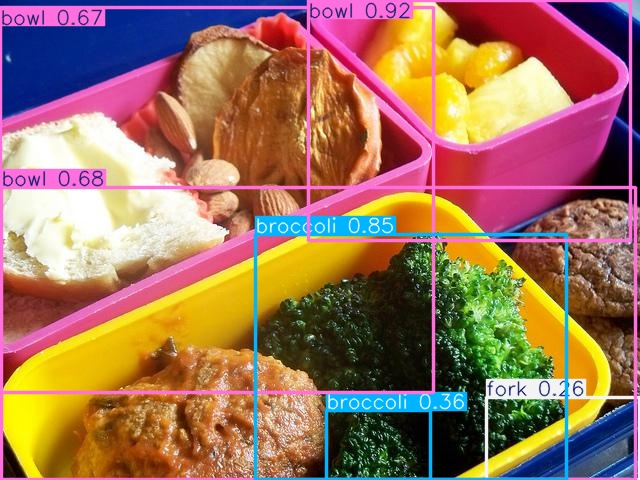

  000000000025.jpg: giraffe (0.88)


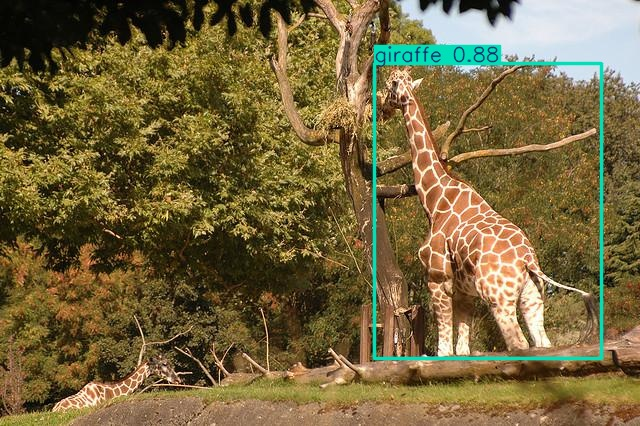

  000000000030.jpg: vase (0.89), potted plant (0.64)


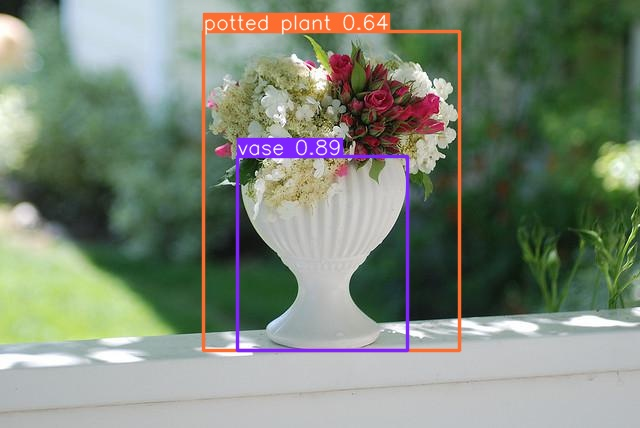

In [4]:
# STAGE 1: Evaluate original COCO128 images
import yaml, cv2, numpy as np, pandas as pd
from IPython.display import display, Image as IPImage

ORIG_IMAGES = dataset_dir / 'images' / 'train2017'
ORIG_LABELS = dataset_dir / 'labels' / 'train2017'
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
original_files = sorted(p for p in ORIG_IMAGES.iterdir() if p.suffix.lower() in IMAGE_EXTS)
assert len(original_files) >= 3, 'COCO128 images missing; run the download setup cell.'
assert ORIG_LABELS.is_dir(), 'Original labels directory is missing.'
# Use identical filenames at all three stages so comparisons are matched.
example_names = [p.name for p in original_files[:3]]
STATS = {}
PREDICTIONS = {}


def write_dataset_yaml(root, name):
    # YOLO expects images/<split> and labels/<split> sibling directories.
    cfg = {'path': str(root.resolve()), 'train': 'images/train2017',
           'val': 'images/train2017', 'nc': len(model.names),
           'names': {int(k): v for k, v in model.names.items()}}
    file = PROJECT_ROOT / f'{name}_dataset.yaml'
    with file.open('w') as f:
        yaml.safe_dump(cfg, f, sort_keys=False)
    return file


def evaluate_stage(stage, root, yaml_file):
    validation = model.val(data=str(yaml_file), split='val', imgsz=640,
                           batch=16, workers=0, verbose=False, plots=False,
                           project=str(PROJECT_ROOT / 'validation'), name=stage, exist_ok=True)
    m = validation.box
    STATS[stage] = {'Precision': float(m.mp), 'Recall': float(m.mr),
                    'mAP@0.5': float(m.map50), 'mAP@0.5:0.95': float(m.map)}
    print(stage, ', '.join(f'{x:.4f}' for x in STATS[stage].values()))

    pred_dir = PROJECT_ROOT / 'prediction_examples' / stage
    pred_dir.mkdir(parents=True, exist_ok=True)
    examples = []
    for fname in example_names:
        img = root / 'images' / 'train2017' / fname
        results = model.predict(source=str(img), imgsz=640, conf=0.25,
                                verbose=False, save=False)[0]
        out = pred_dir / fname
        ok = cv2.imwrite(str(out), results.plot())
        assert ok, f'Could not save {out}'
        detections = []
        for box in results.boxes:
            label = model.names[int(box.cls.item())]
            confidence = float(box.conf.item())
            detections.append((label, confidence))
        desc = ', '.join(f'{label} ({confidence:.2f})' for label, confidence in detections) or 'No detections at conf=0.25'
        examples.append({'image': fname, 'detections': desc, 'path': str(out)})
        print(f'  {fname}: {desc}')
        display(IPImage(filename=str(out), width=550))
    PREDICTIONS[stage] = examples
    return validation

orig_yaml = write_dataset_yaml(dataset_dir, 'original')
orig_result = evaluate_stage('Original', dataset_dir, orig_yaml)



# Stage 2 — Gaussian Blur

Create a blurred copy of **all COCO128 images**.

### Required blur setting
Use a **9 × 9 Gaussian kernel** with standard OpenCV Gaussian blur.

### Your task
1. Read every original image.
2. Apply Gaussian blur.
3. Save the blurred image with the same filename.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector on the blurred dataset.
6. Record the same four metrics.
7. Save at least **3 blurred prediction examples**.

Do not retrain or replace the detector.


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1734.6±387.1 MB/s, size: 52.3 KB)
val: Scanning /content/fvl_project/blurred/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.9Kit/s 0.1s
val: New cache created: /content/fvl_project/blurred/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 5.7it/s 1.4s
                   all        128        929       0.68      0.536      0.618      0.443
Speed: 0.3ms preprocess, 3.8ms inference, 0.0ms loss, 1.1ms postprocess per image
Blurred 0.6802, 0.5358, 0.6176, 0.4434
  000000000009.jpg: bowl (0.92), broccoli (0.88), bowl (0.68), bowl (0.60), bowl (0.60), fork (0.38)


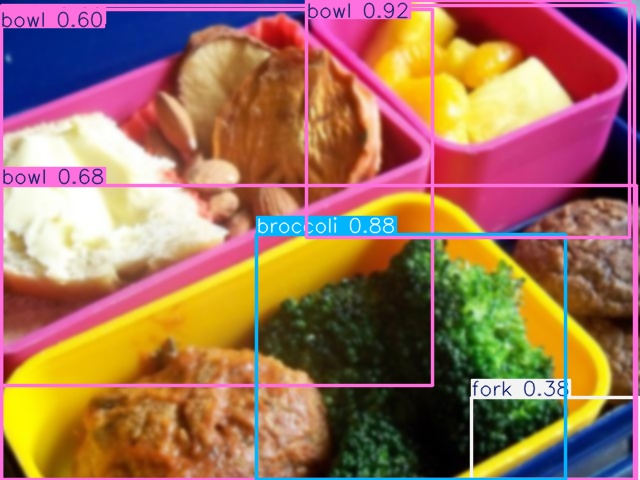

  000000000025.jpg: giraffe (0.87)


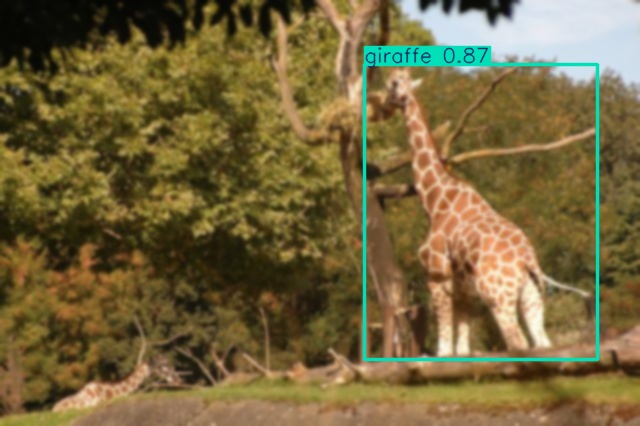

  000000000030.jpg: vase (0.88), potted plant (0.69)


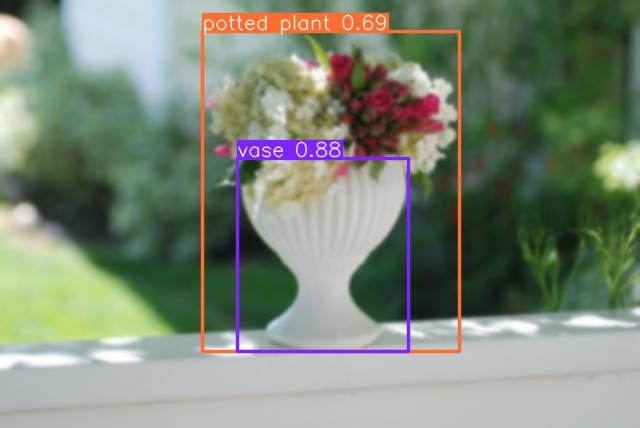

In [5]:
# STAGE 2: 9x9 Gaussian Blur applied to all original images
import shutil
BLURRED_ROOT = PROJECT_ROOT / 'blurred'
blur_images = BLURRED_ROOT / 'images' / 'train2017'
blur_labels = BLURRED_ROOT / 'labels' / 'train2017'
blur_images.mkdir(parents=True, exist_ok=True)
blur_labels.mkdir(parents=True, exist_ok=True)
for original in original_files:
    image = cv2.imread(str(original))
    if image is None:
        raise ValueError(f'Cannot read image: {original}')
    blurred = cv2.GaussianBlur(image, (9, 9), 0)
    if not cv2.imwrite(str(blur_images / original.name), blurred):
        raise IOError(f'Cannot save blurred image: {original.name}')
    label = ORIG_LABELS / f'{original.stem}.txt'
    if label.exists():
        shutil.copy2(label, blur_labels / label.name)
assert len(list(blur_images.iterdir())) == len(original_files)
blur_yaml = write_dataset_yaml(BLURRED_ROOT, 'blurred')
blur_result = evaluate_stage('Blurred', BLURRED_ROOT, blur_yaml)



# Stage 3 — Sharpen the Blurred Images

Apply **one sharpening method** to the Stage 2 blurred images.

You may use a standard sharpening kernel or unsharp masking. Keep the image size unchanged.

### Your task
1. Implement the sharpening operation yourself.
2. Apply it to every blurred image.
3. Save the sharpened images with the same filenames.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector again.
6. Record the same four metrics.
7. Save at least **3 sharpened prediction examples**.

Do not retrain or replace YOLO11n.


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2126.9±520.2 MB/s, size: 62.9 KB)
val: Scanning /content/fvl_project/sharpened/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.8Kit/s 0.1s
val: New cache created: /content/fvl_project/sharpened/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 6.2it/s 1.3s
                   all        128        929      0.647       0.55       0.62      0.449
Speed: 0.3ms preprocess, 3.4ms inference, 0.0ms loss, 1.0ms postprocess per image
Sharpened 0.6470, 0.5502, 0.6196, 0.4490
  000000000009.jpg: bowl (0.92), broccoli (0.88), bowl (0.67), bowl (0.60), bowl (0.59), fork (0.36)


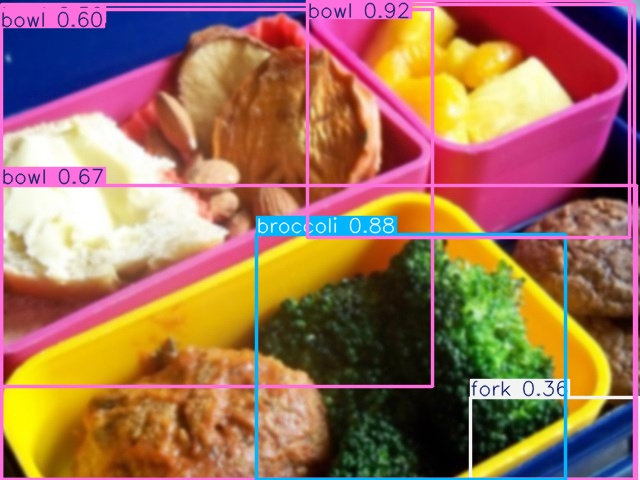

  000000000025.jpg: giraffe (0.87)


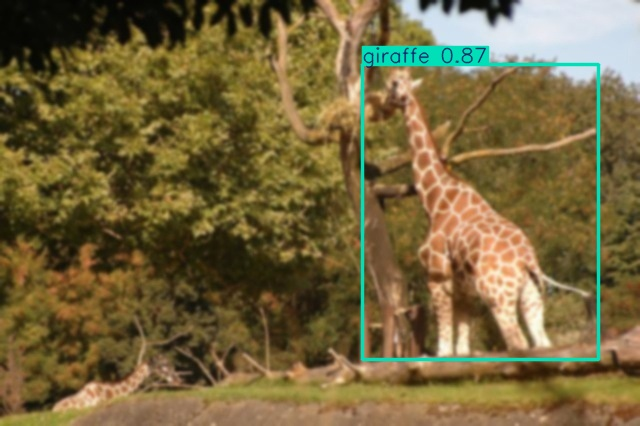

  000000000030.jpg: vase (0.87), potted plant (0.70)


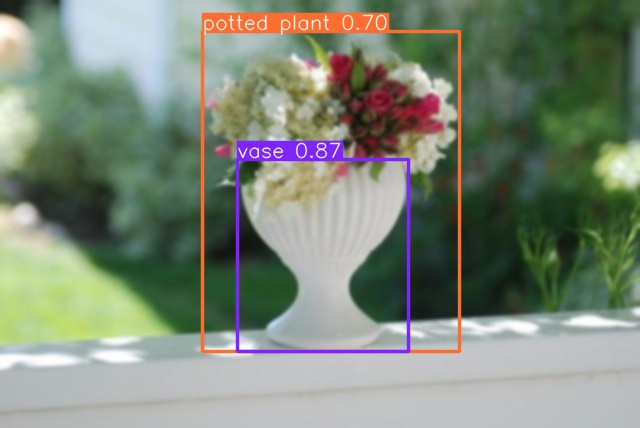

In [6]:
# STAGE 3: Unsharp masking on blurred images (no retraining)
SHARPENED_ROOT = PROJECT_ROOT / 'sharpened'
sharp_images = SHARPENED_ROOT / 'images' / 'train2017'
sharp_labels = SHARPENED_ROOT / 'labels' / 'train2017'
sharp_images.mkdir(parents=True, exist_ok=True)
sharp_labels.mkdir(parents=True, exist_ok=True)
# Unsharp mask: sharp = 1.5 * blurred - 0.5 * GaussianBlur(blurred, (0,0), 1.0)
for original in original_files:
    blurred = cv2.imread(str(blur_images / original.name))
    assert blurred is not None, f'Cannot read blurred image: {original.name}'
    low_frequency = cv2.GaussianBlur(blurred, (0, 0), sigmaX=1.0)
    sharpened = cv2.addWeighted(blurred, 1.5, low_frequency, -0.5, 0)
    if not cv2.imwrite(str(sharp_images / original.name), sharpened):
        raise IOError(f'Cannot save sharpened image: {original.name}')
    label = ORIG_LABELS / f'{original.stem}.txt'
    if label.exists():
        shutil.copy2(label, sharp_labels / label.name)
assert len(list(sharp_images.iterdir())) == len(original_files)
sharp_yaml = write_dataset_yaml(SHARPENED_ROOT, 'sharpened')
sharp_result = evaluate_stage('Sharpened', SHARPENED_ROOT, sharp_yaml)


## Stage 4 — Results generated from the recorded run

The following executed cell displays the results and generates form text from unrounded model metrics. The final summary below provides the reviewed, submission-ready analysis. Deltas in the final written analysis use the four-decimal table values. The retained execution output calculates deltas before rounding, so a few differences vary by 0.0001. Prediction confidence values are rounded to two decimals. Predictions are model outputs, not individually verified ground-truth matches.

In [7]:
# Generate results and form answers from actual model outputs
assert all(s in STATS and s in PREDICTIONS for s in ['Original','Blurred','Sharpened']), 'Run all three stages first.'
stages = ['Original', 'Blurred', 'Sharpened']
df = pd.DataFrame.from_dict(STATS, orient='index').loc[stages]
print('FINAL RESULTS MATRIX')
display(df.style.format('{:.4f}'))

rows = ['Name: Alok Sahni', 'Roll number: G25AIT2138', 'Email: g25ait2138@iitj.ac.in']
for s in stages:
    vals = ', '.join(f'{x:.4f}' for x in df.loc[s].values)
    rows.append(f'Result — {s}: {vals}')
    preds = '; '.join(f"{p['image']}: {p['detections']}" for p in PREDICTIONS[s])
    rows.append(f'Prediction examples — {s}: {preds}')

def metrics_diff(stage_from, stage_to):
    return {k: STATS[stage_to][k] - STATS[stage_from][k] for k in df.columns}

def comparison(diff):
    return '; '.join(f'{key}: {diff[key]:+.4f}' for key in df.columns)

blur_diff = metrics_diff('Original', 'Blurred')
sharp_diff = metrics_diff('Blurred', 'Sharpened')
a = ('A. Effect of blur: Original → Gaussian Blur metric changes: ' + comparison(blur_diff) +
     '. Gaussian blur (9×9) suppresses fine detail and edges; see matched examples: ' +
     '; '.join(f"{PREDICTIONS['Original'][i]['image']} — original [{PREDICTIONS['Original'][i]['detections']}], blurred [{PREDICTIONS['Blurred'][i]['detections']}]" for i in range(3)) +
     '. Positive changes denote increases; negative changes denote decreases.')
b = ('B. Why sharpening? Applied unsharp masking to each blurred image: '
     'sharpened = 1.5×blurred − 0.5×GaussianBlur(blurred, σ=1.0). '
     'This boosts local contrast around edges and may make object boundaries easier for YOLO11n to detect. '
     'It cannot fully reconstruct details lost during blur.')
improved = [k for k,v in sharp_diff.items() if v > 0.0000001]
worse = [k for k,v in sharp_diff.items() if v < -0.0000001]
unchanged = [k for k,v in sharp_diff.items() if abs(v) <= 0.0000001]
c = ('C. Did sharpening help? Blurred → Sharpened metric changes: ' + comparison(sharp_diff) +
     '. Improved: ' + (', '.join(improved) or 'none') +
     '. Worsened: ' + (', '.join(worse) or 'none') +
     '. Unchanged: ' + (', '.join(unchanged) or 'none') +
     '. Matched detections: ' +
     '; '.join(f"{PREDICTIONS['Blurred'][i]['image']} — blurred [{PREDICTIONS['Blurred'][i]['detections']}], sharpened [{PREDICTIONS['Sharpened'][i]['detections']}]" for i in range(3)) + '.')
keep = sharp_diff['mAP@0.5:0.95'] > 0 and sharp_diff['mAP@0.5'] >= 0
d = ('D. Final conclusion: ' +
     ('I would retain unsharp masking for this tested setting, because mAP@0.5:0.95 increased and mAP@0.5 did not decrease relative to blur.' if keep else
      'I would not retain unsharp masking as the default, since it did not improve mAP@0.5:0.95 without lowering mAP@0.5 relative to blur.') +
     ' The conclusion is specific to COCO128, YOLO11n, and the chosen settings; compare images and test on more data before generalizing.')
rows += [a,b,c,d]
form_text = '\n\n'.join(rows)
print('\nGOOGLE FORM — COPY READY\n')
print(form_text)
(PROJECT_ROOT / 'G25AIT2138_CV_Google_Form_Answers.txt').write_text(form_text, encoding='utf-8')
df.to_csv(PROJECT_ROOT / 'G25AIT2138_CV_final_metrics.csv', float_format='%.4f')
print('\nSaved form answers and metrics in:', PROJECT_ROOT)


FINAL RESULTS MATRIX


,Precision,Recall,mAP@0.5,mAP@0.5:0.95
Original,0.6633,0.5894,0.6706,0.5026
Blurred,0.6802,0.5358,0.6176,0.4434
Sharpened,0.6470,0.5502,0.6196,0.4490



GOOGLE FORM — COPY READY

Name: Alok Sahni

Roll number: G25AIT2138

Email: g25ait2138@iitj.ac.in

Result — Original: 0.6633, 0.5894, 0.6706, 0.5026

Prediction examples — Original: 000000000009.jpg: bowl (0.92), broccoli (0.85), bowl (0.68), bowl (0.67), broccoli (0.36), fork (0.26); 000000000025.jpg: giraffe (0.88); 000000000030.jpg: vase (0.89), potted plant (0.64)

Result — Blurred: 0.6802, 0.5358, 0.6176, 0.4434

Prediction examples — Blurred: 000000000009.jpg: bowl (0.92), broccoli (0.88), bowl (0.68), bowl (0.60), bowl (0.60), fork (0.38); 000000000025.jpg: giraffe (0.87); 000000000030.jpg: vase (0.88), potted plant (0.69)

Result — Sharpened: 0.6470, 0.5502, 0.6196, 0.4490

Prediction examples — Sharpened: 000000000009.jpg: bowl (0.92), broccoli (0.88), bowl (0.67), bowl (0.60), bowl (0.59), fork (0.36); 000000000025.jpg: giraffe (0.87); 000000000030.jpg: vase (0.87), potted plant (0.70)

A. Effect of blur: Original → Gaussian Blur metric changes: Precision: +0.0169; Recall: -

## Final results table

| Stage | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---:|---:|---:|---:|
| Original / Baseline | 0.6633 | 0.5894 | 0.6706 | 0.5026 |
| Gaussian Blur | 0.6802 | 0.5358 | 0.6176 | 0.4434 |
| Sharpened | 0.6470 | 0.5502 | 0.6196 | 0.4490 |

Deltas in the final written analysis use the four-decimal table values. The retained execution output calculates deltas before rounding, so a few differences vary by 0.0001. Prediction confidence values are rounded to two decimals. Predictions are model outputs, not individually verified ground-truth matches.

## Matched prediction examples

The nine annotated images are embedded in the Stage 1–3 outputs above.

### Original / Baseline

1. 000000000009.jpg: bowl (0.92), broccoli (0.85), bowl (0.68), bowl (0.67), broccoli (0.36), fork (0.26). Six detections, including two broccoli predictions.
2. 000000000025.jpg: giraffe (0.88). One giraffe prediction.
3. 000000000030.jpg: vase (0.89), potted plant (0.64). Two predictions.

### Gaussian Blur

1. 000000000009.jpg: bowl (0.92), broccoli (0.88), bowl (0.68), bowl (0.60), bowl (0.60), fork (0.38). Six detections; the second broccoli prediction is absent and there are four bowl predictions instead of three.
2. 000000000025.jpg: giraffe (0.87). The giraffe remains detected with slightly lower reported confidence.
3. 000000000030.jpg: vase (0.88), potted plant (0.69). Both labels remain; vase confidence decreases while plant confidence increases.

### Sharpened

1. 000000000009.jpg: bowl (0.92), broccoli (0.88), bowl (0.67), bowl (0.60), bowl (0.59), fork (0.36). Six detections; the second broccoli prediction does not return. Fork confidence decreases from 0.38 to 0.36.
2. 000000000025.jpg: giraffe (0.87). The same label and confidence rounded to two decimal places as in the blurred example.
3. 000000000030.jpg: vase (0.87), potted plant (0.70). Plant confidence rises from 0.69 to 0.70; vase confidence falls from 0.88 to 0.87.

## A. Effect of blur

1. From Original to Gaussian Blur, precision rises from 0.6633 to 0.6802 (+0.0169), but recall falls from 0.5894 to 0.5358 (-0.0536). Higher precision alone therefore does not indicate an overall improvement.
2. mAP@0.5 falls from 0.6706 to 0.6176 (-0.0530) and mAP@0.5:0.95 falls from 0.5026 to 0.4434 (-0.0592), approximately 7.9% and 11.8% below baseline respectively.
3. Gaussian smoothing weakens fine edges and texture, which can affect classification and box localisation. This is a plausible explanation for the degradation; aggregate metrics do not prove which individual predictions became false positives or false negatives.
4. In 000000000009.jpg the second broccoli prediction (0.36) disappears, although the total remains six detections. The giraffe remains detected (0.88 to 0.87), and the vase/plant labels remain with mixed confidence changes. These three examples illustrate variation rather than establish a dataset-wide small-object effect.

## B. Why sharpening?

1. I used unsharp masking on every Stage 2 blurred image, with amount 0.5 and Gaussian sigma 1.0: sharpened = 1.5 * blurred - 0.5 * GaussianBlur(blurred, (0, 0), 1.0).
2. The implementation uses cv2.addWeighted(blurred, 1.5, low_frequency, -0.5, 0). With uint8 inputs, OpenCV saturates values to the valid image range. Image dimensions and labels remain unchanged.
3. Adding a scaled high-frequency residual increases local edge contrast and may help the detector use boundaries that survived the blur. It does not reconstruct all lost detail and can amplify noise or compression artefacts.

## C. Did sharpening help?

1. Sharpening improves recall from 0.5358 to 0.5502 (+0.0144), mAP@0.5 from 0.6176 to 0.6196 (+0.0020), and mAP@0.5:0.95 from 0.4434 to 0.4490 (+0.0056). These changes are calculated from the four-decimal results table.
2. Precision worsens from 0.6802 to 0.6470 (-0.0332), also below the original 0.6633. The recall/mAP gains therefore come with a precision trade-off. These aggregate values do not identify the specific false positives responsible.
3. Both mAP scores remain below baseline: 0.6196 versus 0.6706 and 0.4490 versus 0.5026. About 9.5% of the mAP@0.5:0.95 loss is recovered (0.0056/0.0592), so the improvement is limited.
4. The three example images retain six, one and two detections respectively after sharpening. The second broccoli does not return; fork confidence falls from 0.38 to 0.36. Plant confidence rises from 0.69 to 0.70 while vase confidence falls from 0.88 to 0.87. Confidence changes alone do not prove improved box accuracy, and these examples need not reproduce the dataset-wide recall trend.

## D. Final conclusion

I would keep sharpening as an optional step for this tested pipeline. It improves recall and both mAP scores compared with blur alone, but precision drops from 0.6802 to 0.6470. The mAP@0.5:0.95 gain is only 0.0056 and performance remains below the original images. I would validate the trade-off on independent images before enabling it by default, especially where false positives are costly. Improving image capture should remain the priority.



## Prediction overview

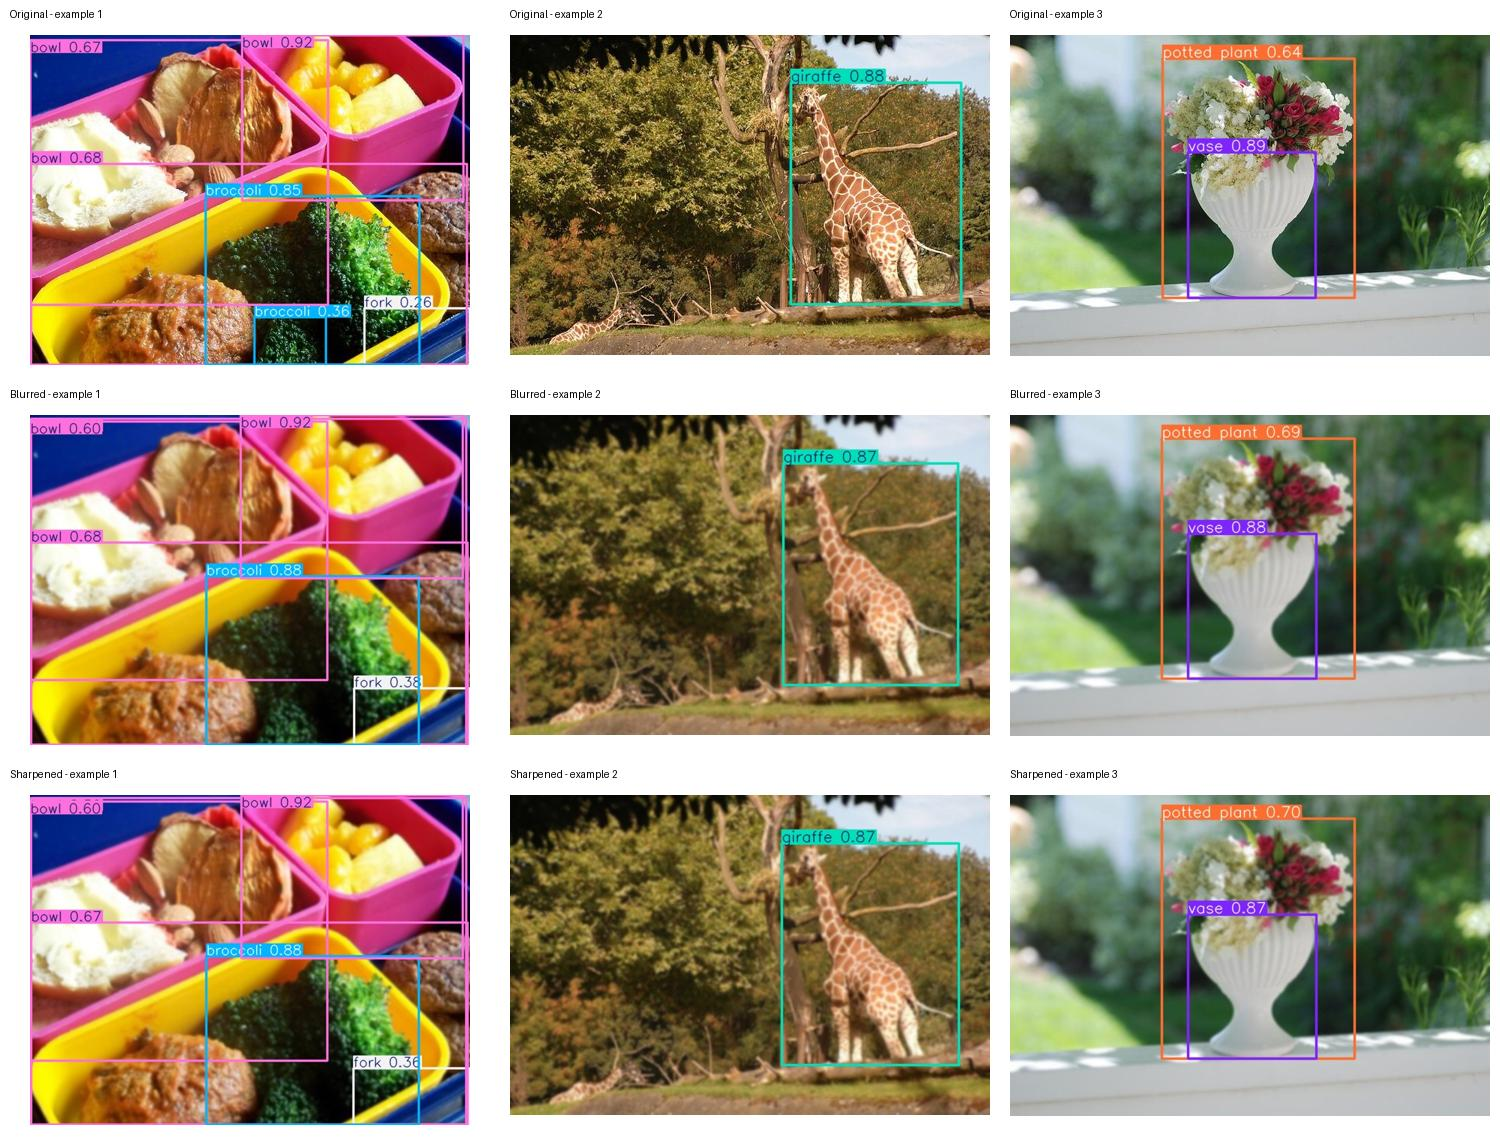

## Verification before submission

- Confirm all three metric rows are populated by actual validation runs.
- Check 3 plotted prediction examples for **each** stage (9 images total), using identical image filenames.
- Compare detection classes and confidence carefully; reported text is raw predictions, not a guaranteed ground-truth correctness assessment.
- Download **this executed notebook** from Colab and submit it along with the separate Google Form.
- The text file generated by Stage 4 is for copy/paste; this notebook does **not** submit the form automatically.



# Submission

Submit:
1. Completed `.ipynb` with final results table and with at least 3 prediction examples from each stage: Original, Blurred, Sharpened
2. Google Form for Results, Prediction examples and Analysis submission

Use your roll number in every submitted filename.
Students are requested to submit in time 1 marks will be deducted per day for late submission

Deadline: Sun, 25 October 2026, 11:59 P.M.
